# Headless MRiLab spectrum generation

Generate simulated spectra and ground truth at explicit `(x, y, z)` voxel-center indices. This notebook does not open the GUI. Convert results to plot-ready NIfTI-MRS objects, and optionally save them with ground-truth sidecars.

In [1]:
from pathlib import Path
import os

project_root = Path.cwd()
if not (project_root / 'data/skeletons/MRiLab').is_dir():
    project_root = project_root.parent
os.chdir(project_root)

from simulation.headless import results_to_nifti_mrs, simulate_batch

/Users/wclarke/Documents/Python/MRS-Digital-Phantom/.pixi/envs/default/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Settings

These values mirror the GUI's Simulation Settings and Voxel Settings. The selected basis is Siemens PRESS at TE 97 ms.

In [ ]:
settings = {
    'path2basis': '/Users/wclarke/Downloads/LCM_basis/SH_PRESS_TE97.BASIS',
    'basis_set_settings': {
        'vendor': 'Siemens',
        'localization': 'PRESS',
        'TE': 97,
    },
    'voxel_size_mm': (10.0, 10.0, 10.0),
    'simulation_params': {
        'spectral_points': 2048,
        'TR': 2000.0,
        'bandwidth': 2000.0,
        'noise_level': 1.0,
        'mm_level': 25.0,
        'mm_json_file': './data/macromolecules/mm_params.json',
        'lipid_amp_factor': 40.0,
        'lipid_sigma': 5.0,
        'lipid_phase_min': -180.0,
        'lipid_phase_max': 180.0,
        'lipid_lw_min': 30.0,
        'lipid_lw_max': 50.0,
        'water_amp_factor': 5.0,
        'water_phase_min': -180.0,
        'water_phase_max': 180.0,
        'water_damping_min': 0.0,
        'water_damping_max': 50.0,
        'shim_amplitude_hz': 3.0,
        'shim_corr_length': 1.0,
        'shim_boundary_amp_factor': 1.5,
        'shim_boundary_smoothing': 2.0,
    },
}

# Replace these with valid zero-based (x, y, z) indices in the MRiLab array.
positions = [(100, 108, 80), (100, 108, 80) ,(110, 108, 80)]
seed = 1234 # Set to `None` for no seed - different each execution. Each position will have a different draw even if defined seed.
nifti_output_dir = None  # For example: './outputs/headless_batch'
total_components = None  # None means all components when saving
individual_components = []

## Generate

Simulation returns spectra and ground truth in memory. Convert them to NIfTI-MRS objects for plotting; set `nifti_output_dir` to also save NIfTI files and sidecars.

In [43]:
results = simulate_batch(
    positions=positions,
    settings=settings,
    seed=seed,
)

for res in results:
    print(res['ground_truth']['tissue_fractions'])


Metabolites to ignore from basisset: [np.str_('EA'), np.str_('CrCH2'), np.str_('bHG'), np.str_('Ser'), np.str_('Ala'), np.str_('Cystat')]
Loading lipid basis set from cache: ./simulation/lipids/lipids_cache/7ab4eec1c3d73b7c902cad3c674ee819.mat
Loading lipid basis set from cache: ./simulation/lipids/lipids_cache/7ab4eec1c3d73b7c902cad3c674ee819.mat
Loading lipid basis set from cache: ./simulation/lipids/lipids_cache/7ab4eec1c3d73b7c902cad3c674ee819.mat
{'Background': 0.0, 'WM': 0.1940000057220459, 'GM': 0.8060000538825989, 'CSF': 0.0, 'Fat': 0.0, 'Skull': 0.0}
{'Background': 0.0, 'WM': 0.1940000057220459, 'GM': 0.8060000538825989, 'CSF': 0.0, 'Fat': 0.0, 'Skull': 0.0}
{'Background': 0.0, 'WM': 0.9770000576972961, 'GM': 0.023000001907348633, 'CSF': 0.0, 'Fat': 0.0, 'Skull': 0.0}


## Convert, plot, and optionally save

The converter returns a total `NIFTI_MRS` object and selected component objects for each voxel. With no output directory, nothing is written; with one set, the objects and sidecars are saved and remain available here.

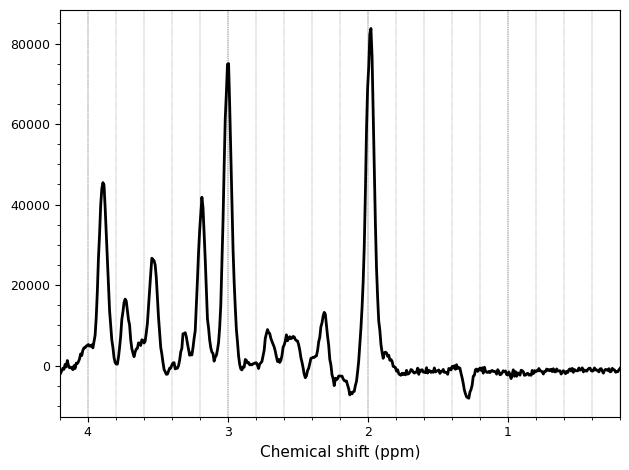

In [45]:
nifti_results = results_to_nifti_mrs(
    results,
    output_dir=nifti_output_dir,
    total_components=total_components,
    individual_components=individual_components,
)

_ = nifti_results[1]['total'].plot()